In [4]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso

In [5]:
insurance_data = pd.read_csv("insurance.csv");

X = insurance_data.drop(columns=["charges", "region"]);
y = insurance_data['charges'];
X["sex"] = X['sex'].map({"male": 1, "female": 0});
X['smoker'] = X['smoker'].map({"yes": 1, "no": 0});

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [15]:
from sklearn.metrics import mean_squared_error

alpha = [0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 100]

mses = []

for a in alpha: 
    lasso_model = Lasso(alpha=a)
    
    lasso_model.fit(X_train, y_train)

    y_pred = lasso_model.predict(X_test);
    mse = mean_squared_error(y_test, y_pred);

    print(f"MSE: of a = {a} is", mse);

    mses.append(mse)

MSE: of a = 0.001 is 33979260.34265196
MSE: of a = 0.1 is 33979586.354544334
MSE: of a = 1 is 33982559.95145963
MSE: of a = 2 is 33985623.39499242
MSE: of a = 5 is 33991677.761373304
MSE: of a = 10 is 34002033.5294535
MSE: of a = 20 is 34023742.37422405
MSE: of a = 30 is 34046780.96380816
MSE: of a = 40 is 34071149.29820583
MSE: of a = 50 is 34096847.37741704
MSE: of a = 100 is 34245283.94567649


<Axes: >

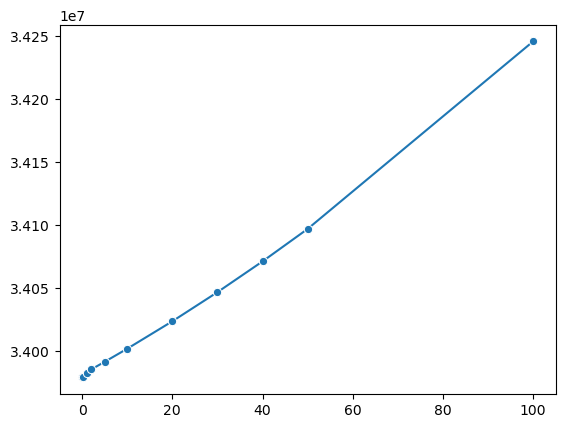

In [16]:
sns.lineplot(x=alpha, y=mses, marker="o")